# Math to Deep Learning with PyTorch: Step-by-Step Notebooks
## Part 3 — Building a Small Neural Network in PyTorch

### 📚 Series Navigation

| Part | Notebook |
|---|---|
| 1 | [Derivatives, Gradients and Backpropagation](https://www.kaggle.com/code/kupershtein/math-to-dl-with-pytorch-part-1-derivatives) |
| 2 | [Activation Functions and the Chain Rule](https://www.kaggle.com/code/kupershtein/math-to-dl-with-pytorch-part-2-activation-func) | 
| **3** | **Building a Small Neural Network in PyTorch** |
| 4 | [Loss Functions, Gradient Descent and Optimization](https://www.kaggle.com/code/kupershtein/math-to-dl-with-pytorch-part-4-loss-gd-optimiz) |
| 5 | [Training Neural Networks End-to-End in PyTorch](hhttps://www.kaggle.com/code/kupershtein/math-to-dl-with-pytorch-part-5-end2end-nn-training) |


## Goal

From the previous parts, we know $z=wx+b$ and $a=\phi(z)$. Now we connect several neurons into a small network.

After this notebook, you should understand how one neuron handles multiple inputs, how neurons form a layer, what $W$ and $b$ mean, how to do a manual forward pass, how `nn.Linear` implements it, how to define `nn.Module` and `forward()`, what a basic training loop looks like, and why hidden layers and nonlinearity matter for XOR.

## Setup

In [1]:
import torch
from torch import nn
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

torch.manual_seed(42)
print("PyTorch version:", torch.__version__)

PyTorch version: 2.10.0+cpu


# 1. One Neuron with Multiple Inputs

Suppose one neuron has two inputs: $x_1,x_2$. Then $z=w_1x_1+w_2x_2+b$, or in vector form $z=\mathbf{w}^\top\mathbf{x}+b$.

In [2]:
x=torch.tensor([2.0,3.0]); w=torch.tensor([0.5,-1.0]); b=torch.tensor(1.0)
z=(w*x).sum()+b
print("x =",x); print("w =",w); print("b =",b); print("z =",z.item())

x = tensor([2., 3.])
w = tensor([ 0.5000, -1.0000])
b = tensor(1.)
z = -1.0


# 2. From One Neuron to a Layer

With **3 neurons**, each neuron has its own weights. The whole layer can be written as $\mathbf{z}=W\mathbf{x}+\mathbf{b}$. For two inputs and three neurons, $W\in\mathbb{R}^{3\times2}$.

In [3]:
x=torch.tensor([2.0,3.0])
W=torch.tensor([[0.5,-1.0],[1.0,0.2],[-0.3,0.8]])
b=torch.tensor([1.0,0.0,-0.5])
z=W@x+b
print("W shape:",W.shape); print("x shape:",x.shape); print("b shape:",b.shape); print("z shape:",z.shape); print("z =",z)

W shape: torch.Size([3, 2])
x shape: torch.Size([2])
b shape: torch.Size([3])
z shape: torch.Size([3])
z = tensor([-1.0000,  2.6000,  1.3000])


# 3. Manual Forward Pass: 2 → 3 → 1

We build `2 inputs → 3 hidden neurons → 1 output`: $\mathbf{h}=\operatorname{ReLU}(W_1\mathbf{x}+\mathbf{b}_1)$ and $\hat y=W_2\mathbf{h}+b_2$. First we do it without `nn.Module`.

In [4]:
x=torch.tensor([1.0,2.0])
W1=torch.tensor([[0.5,-0.2],[0.8,0.4],[-0.3,0.9]])
b1=torch.tensor([0.1,-0.2,0.0])
W2=torch.tensor([[0.7,-0.5,0.3]]); b2=torch.tensor([0.2])
z1=W1@x+b1; h=torch.relu(z1); prediction=W2@h+b2
print("z1 =",z1); print("hidden activation =",h); print("prediction =",prediction.item())

z1 = tensor([0.2000, 1.4000, 1.5000])
hidden activation = tensor([0.2000, 1.4000, 1.5000])
prediction = 0.09000001847743988


# 4. Diagram of a Small Neural Network

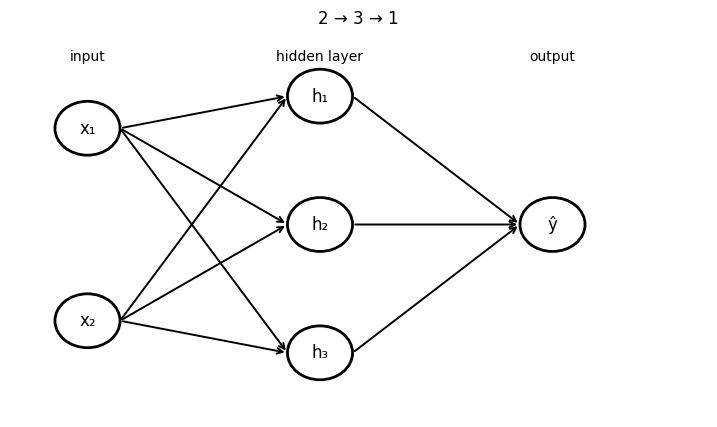

In [5]:
fig,ax=plt.subplots(figsize=(9,5)); ax.set_xlim(0,9); ax.set_ylim(0,6); ax.axis("off")
inputs=[(1,4.5,"x₁"),(1,1.5,"x₂")]; hidden=[(4,5,"h₁"),(4,3,"h₂"),(4,1,"h₃")]; output=[(7,3,"ŷ")]
for px,py,label in inputs+hidden+output:
    c=Circle((px,py),0.42,fill=False,linewidth=2); ax.add_patch(c); ax.text(px,py,label,ha="center",va="center",fontsize=12)
for ix,iy,_ in inputs:
    for hx,hy,_ in hidden: ax.annotate("",xy=(hx-0.42,hy),xytext=(ix+0.42,iy),arrowprops=dict(arrowstyle="->",lw=1.4))
for hx,hy,_ in hidden: ax.annotate("",xy=(6.58,3),xytext=(hx+0.42,hy),arrowprops=dict(arrowstyle="->",lw=1.4))
ax.text(1,5.55,"input",ha="center"); ax.text(4,5.55,"hidden layer",ha="center"); ax.text(7,5.55,"output",ha="center")
plt.title("2 → 3 → 1"); plt.show()

# 5. The Same Computation with `nn.Linear`

`nn.Linear(in_features, out_features)` implements $y=xW^\top+b$. For `nn.Linear(2,3)`, `weight` has shape `(3,2)` and `bias` has shape `(3,)`.

In [6]:
layer=nn.Linear(2,3)
print(layer); print("weight shape:",layer.weight.shape); print("bias shape:",layer.bias.shape)
x=torch.tensor([[1.0,2.0]]); output=layer(x)
print("input shape:",x.shape); print("output shape:",output.shape); print("output =",output)

Linear(in_features=2, out_features=3, bias=True)
weight shape: torch.Size([3, 2])
bias shape: torch.Size([3])
input shape: torch.Size([1, 2])
output shape: torch.Size([1, 3])
output = tensor([[1.3702, 1.5487, 0.7538]], grad_fn=<AddmmBackward0>)


# 6. Building a Model with `nn.Module`

PyTorch models usually derive from `nn.Module`. We create layers in `__init__()` and describe data flow in `forward()`.

In [7]:
class SmallNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.hidden=nn.Linear(2,4)
        self.activation=nn.Tanh()
        self.output=nn.Linear(4,1)
    def forward(self,x):
        x=self.hidden(x)
        x=self.activation(x)
        x=self.output(x)
        return x

model=SmallNet(); print(model)

SmallNet(
  (hidden): Linear(in_features=2, out_features=4, bias=True)
  (activation): Tanh()
  (output): Linear(in_features=4, out_features=1, bias=True)
)


# 7. Model Parameters and Their Shapes

Each `nn.Linear` has trainable `weight` and `bias` tensors. PyTorch automatically exposes them through `model.parameters()`.

In [8]:
for name,p in model.named_parameters(): print(f"{name:15s} shape={tuple(p.shape)}")

hidden.weight   shape=(4, 2)
hidden.bias     shape=(4,)
output.weight   shape=(1, 4)
output.bias     shape=(1,)


# 8. Practical Example: XOR

XOR is a classic tiny problem that **cannot be separated correctly by one straight line**.

| $x_1$ | $x_2$ | $y$ |
|---:|---:|---:|
| 0 | 0 | 0 |
| 0 | 1 | 1 |
| 1 | 0 | 1 |
| 1 | 1 | 0 |

It clearly demonstrates why hidden layers and nonlinear activations matter.

In [9]:
X=torch.tensor([[0.,0.],[0.,1.],[1.,0.],[1.,1.]])
y=torch.tensor([[0.],[1.],[1.],[0.]])
print("X:"); print(X); print("\ny:"); print(y)

X:
tensor([[0., 0.],
        [0., 1.],
        [1., 0.],
        [1., 1.]])

y:
tensor([[0.],
        [1.],
        [1.],
        [0.]])


# 9. Why One Linear Layer Is Not Enough for XOR

First we try `nn.Linear(2,1)` with no hidden layer. It is only a linear transformation, so it cannot solve XOR correctly.

In [10]:
torch.manual_seed(42)
linear_model=nn.Linear(2,1); criterion=nn.BCEWithLogitsLoss(); optimizer=torch.optim.SGD(linear_model.parameters(),lr=0.2)
linear_losses=[]
for epoch in range(1000):
    optimizer.zero_grad(); logits=linear_model(X); loss=criterion(logits,y); loss.backward(); optimizer.step(); linear_losses.append(loss.item())
with torch.no_grad():
    probabilities=torch.sigmoid(linear_model(X)); predictions=(probabilities>=0.5).float(); accuracy=(predictions==y).float().mean()
print("Probabilities:"); print(probabilities); print("Predictions:"); print(predictions); print("Accuracy:",accuracy.item())

Probabilities:
tensor([[0.5000],
        [0.5000],
        [0.5000],
        [0.5000]])
Predictions:
tensor([[0.],
        [0.],
        [0.],
        [1.]])
Accuracy: 0.25


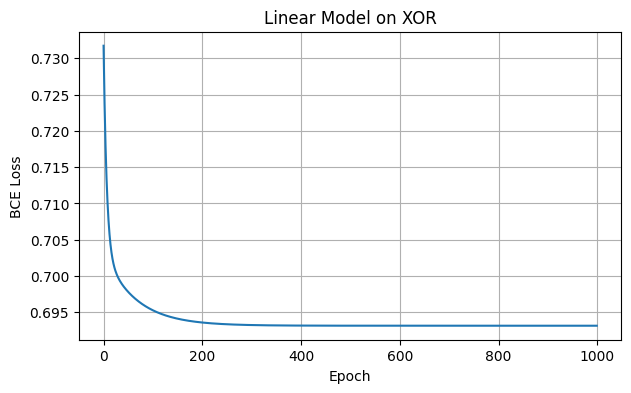

In [11]:
plt.figure(figsize=(7,4)); plt.plot(linear_losses); plt.xlabel("Epoch"); plt.ylabel("BCE Loss"); plt.title("Linear Model on XOR"); plt.grid(True); plt.show()

# 10. Training a Small Neural Network

Now we use `2 → Linear(2,4) → Tanh → Linear(4,1)`. For binary classification we briefly use `nn.BCEWithLogitsLoss()`. Loss functions are covered in detail in Part 4.

## 10.1. Complete Training Loop

Standard training loop:
```python
optimizer.zero_grad()
prediction = model(X)
loss = criterion(prediction, y)
loss.backward()
optimizer.step()
```

In [12]:
torch.manual_seed(7)
model=SmallNet(); criterion=nn.BCEWithLogitsLoss(); optimizer=torch.optim.Adam(model.parameters(),lr=0.1)
loss_history=[]
for epoch in range(1500):
    optimizer.zero_grad(); logits=model(X); loss=criterion(logits,y); loss.backward(); optimizer.step(); loss_history.append(loss.item())
print("Final loss:",loss_history[-1])

Final loss: 8.882683323463425e-05


## 10.2. How the Loss Changes

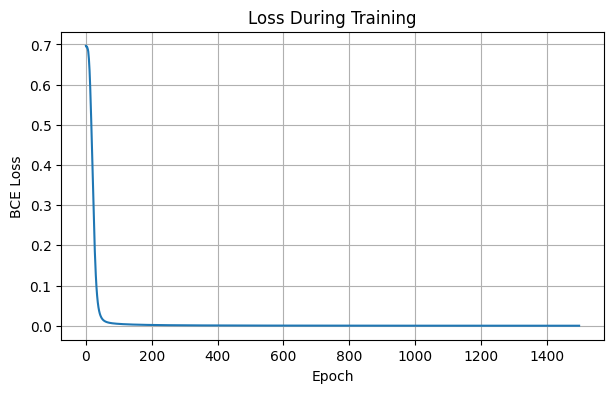

In [13]:
plt.figure(figsize=(7,4)); plt.plot(loss_history); plt.xlabel("Epoch"); plt.ylabel("BCE Loss"); plt.title("Loss During Training"); plt.grid(True); plt.show()

## 10.3. Checking Predictions

In [14]:
with torch.no_grad():
    logits=model(X); probabilities=torch.sigmoid(logits); predictions=(probabilities>=0.5).float(); accuracy=(predictions==y).float().mean()
print("Probabilities:"); print(probabilities); print("\nPredictions:"); print(predictions); print("\nTargets:"); print(y); print("\nAccuracy:",accuracy.item())

Probabilities:
tensor([[1.4851e-06],
        [9.9984e-01],
        [9.9996e-01],
        [1.5357e-04]])

Predictions:
tensor([[0.],
        [1.],
        [1.],
        [0.]])

Targets:
tensor([[0.],
        [1.],
        [1.],
        [0.]])

Accuracy: 1.0


# 11. Inspecting Hidden Activations

We inspect the representation produced by the hidden layer. Nonlinearity maps XOR inputs into a new space where the output layer can separate the classes more easily.

Hidden activations:
tensor([[ 0.6149,  0.7694,  0.9102,  0.8282],
        [-0.9975, -0.9880,  1.0000,  1.0000],
        [-0.9959,  1.0000, -0.9595, -0.9819],
        [-1.0000,  0.9889,  0.9920,  0.9971]])


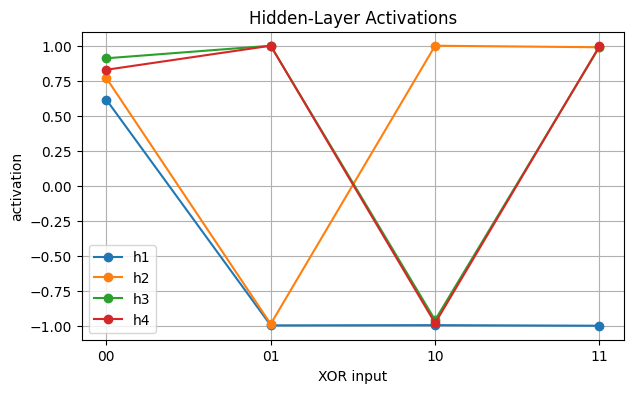

In [15]:
with torch.no_grad(): hidden_before=model.hidden(X); hidden_after=model.activation(hidden_before)
print("Hidden activations:"); print(hidden_after)
plt.figure(figsize=(7,4))
for i in range(hidden_after.shape[1]): plt.plot(range(len(X)),hidden_after[:,i].numpy(),marker="o",label=f"h{i+1}")
plt.xticks(range(len(X)),["00","01","10","11"]); plt.xlabel("XOR input"); plt.ylabel("activation"); plt.title("Hidden-Layer Activations"); plt.legend(); plt.grid(True); plt.show()

# 12. What Happens During `loss.backward()`?

`loss.backward()` moves backward through output Linear → Tanh → hidden Linear and computes gradients for all trainable parameters. Then `optimizer.step()` updates the weights.

In [16]:
model.zero_grad(); logits=model(X); loss=criterion(logits,y); loss.backward()
for name,p in model.named_parameters():
    print(name); print("mean |gradient| =",p.grad.abs().mean().item()); print()

hidden.weight
mean |gradient| = 1.8506034393794835e-06

hidden.bias
mean |gradient| = 1.6643582512188004e-07

output.weight
mean |gradient| = 2.3426491679856554e-05

output.bias
mean |gradient| = 1.1155840184073895e-05



In [17]:
print(model.state_dict().keys())

odict_keys(['hidden.weight', 'hidden.bias', 'output.weight', 'output.bias'])


# Checks

# 13. Small Exercises

### Exercise 1
Change `nn.Linear(2,4)` to `nn.Linear(2,2)`. Does XOR still train reliably?

### Exercise 2
Replace `nn.Tanh()` with `nn.ReLU()`.

### Exercise 3
Try learning rates `0.01`, `0.1`, `0.5`.

### Exercise 4
Print `model.state_dict()` and identify all weights and biases.

### Exercise 5
Add another hidden layer `Linear(4,4) → Tanh()`.

# 14. Quick Cheat Sheet

| Concept | Meaning |
|---|---|
| neuron | $w^\top x+b$ followed by activation |
| layer | several neurons evaluated together |
| weight matrix | all weights of a layer |
| bias vector | one bias per neuron |
| hidden layer | intermediate layer between input and output |
| `nn.Linear` | built-in linear layer |
| `nn.Module` | base class for PyTorch models |
| `forward()` | defines the forward pass |
| optimizer | updates parameters |
| training loop | forward → loss → backward → update |

# Next Steps

We can now build layers, create an `nn.Module`, implement `forward()`, compute loss, call `backward()`, and update parameters.

## ➡️ Next Notebook
### [Part 4 — Loss Functions, Gradient Descent and Optimization](https://www.kaggle.com/code/kupershtein/math-to-dl-with-pytorch-part-4-loss-gd-optimiz)

1. [Part 1 — Derivatives, Gradients and Backpropagation](https://www.kaggle.com/code/kupershtein/math-to-dl-with-pytorch-part-1-derivatives)  
2. [Part 2 — Activation Functions and the Chain Rule](https://www.kaggle.com/code/kupershtein/math-to-dl-with-pytorch-part-2-activation-func)  
3. **Part 3 — Building a Small Neural Network in PyTorch** ← you are here  
4. [Part 4 — Loss Functions, Gradient Descent and Optimization](https://www.kaggle.com/code/kupershtein/math-to-dl-with-pytorch-part-4-loss-gd-optimiz))  
5. [Part 5 — Training Neural Networks End-to-End in PyTorch](hhttps://www.kaggle.com/code/kupershtein/math-to-dl-with-pytorch-part-5-end2end-nn-training)
